SHOOTING METHOD: RESIDUAL CALCULATIONS
Initial curvature (s)    Residual R(s)       
-------------------------------------------------------
0.100000                 -0.5507916675       
0.200000                 -0.2868006802       
0.300000                 -0.0654437482       
0.500000                 0.3137254621        
2.000000                 2.3103807469        


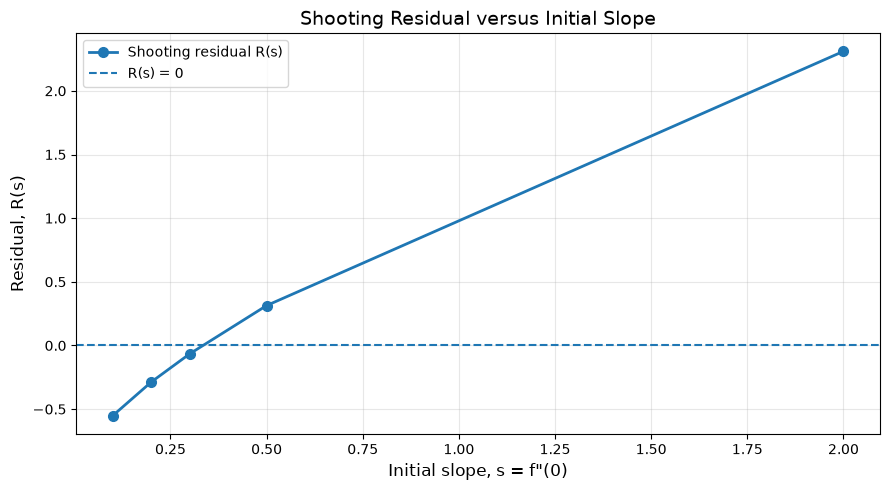

BISECTION METHOD
Iter    s_lower        s_upper        s_mid          R(s_mid)          Error          
-------------------------------------------------------------------------------------
1       0.30000000     0.50000000     0.40000000     1.32134283e-01    1.00000000e-01 
2       0.30000000     0.40000000     0.35000000     3.57063604e-02    5.00000000e-02 
3       0.30000000     0.35000000     0.32500000     -1.42195819e-02   2.50000000e-02 
4       0.32500000     0.35000000     0.33750000     1.08975211e-02    1.25000000e-02 
5       0.32500000     0.33750000     0.33125000     -1.62153542e-03   6.25000000e-03 
6       0.33125000     0.33750000     0.33437500     4.64774305e-03    3.12500000e-03 
7       0.33125000     0.33437500     0.33281250     1.51555660e-03    1.56250000e-03 
8       0.33125000     0.33281250     0.33203125     -5.23742913e-05   7.81250000e-04 
9       0.33203125     0.33281250     0.33242187     7.31744692e-04    3.90625000e-04 
10      0.33203125     0.33

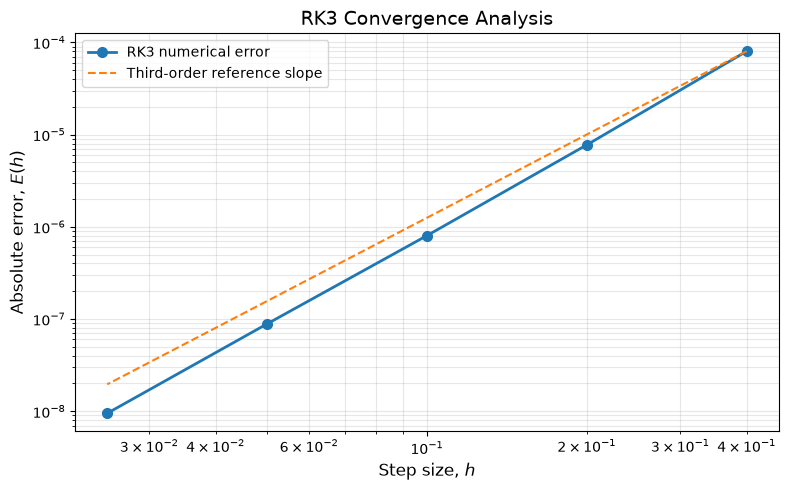

SOLUTION PARAMETERS
----------------------------------------
Initial curvature f''(0): 0.33205733655850056
Final velocity f'(eta_inf): 0.9999999999994605
Final similarity function: 8.279212371740115
Final curvature f''(eta_inf): 8.442739891148729e-09


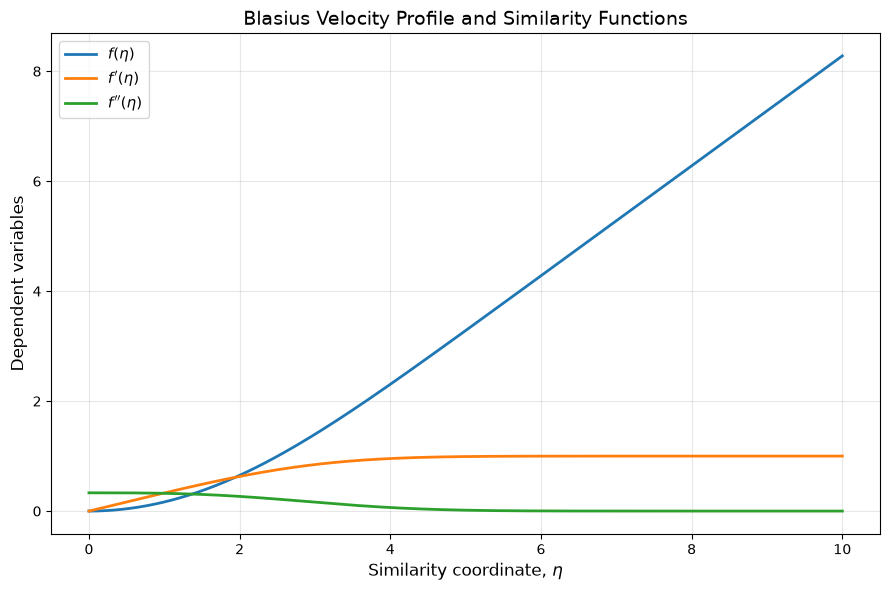

SHOOTING PARAMETER CONVERGENCE: RK3 vs RK4
h           RK3 s                 RK3 Error           RK4 s                 RK4 Error           
---------------------------------------------------------------------------------------------------------
0.4000      0.331977144771        8.019143e-05        0.332058815839        1.479639e-06        
0.2000      0.332049598249        7.737951e-06        0.332057457451        1.212507e-07        
0.1000      0.332056533400        8.027995e-07        0.332057345611        9.410519e-09        
0.0500      0.332057247592        8.860754e-08        0.332057337757        1.556851e-09        
0.0250      0.332057326701        9.498967e-09        0.332057337239        1.038803e-09        

OBSERVED ORDER OF ACCURACY
Step-size transition          RK3 Order      RK4 Order      
0.4000 -> 0.20003.373425       3.609180       
0.2000 -> 0.10003.268840       3.687575       
0.1000 -> 0.05003.179538       2.595644       
0.0500 -> 0.02503.221587       0.583709

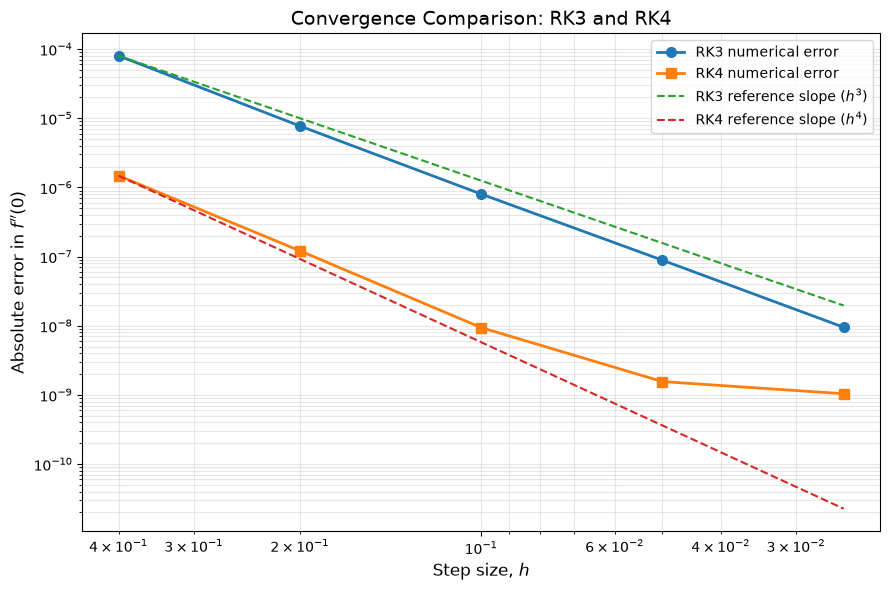

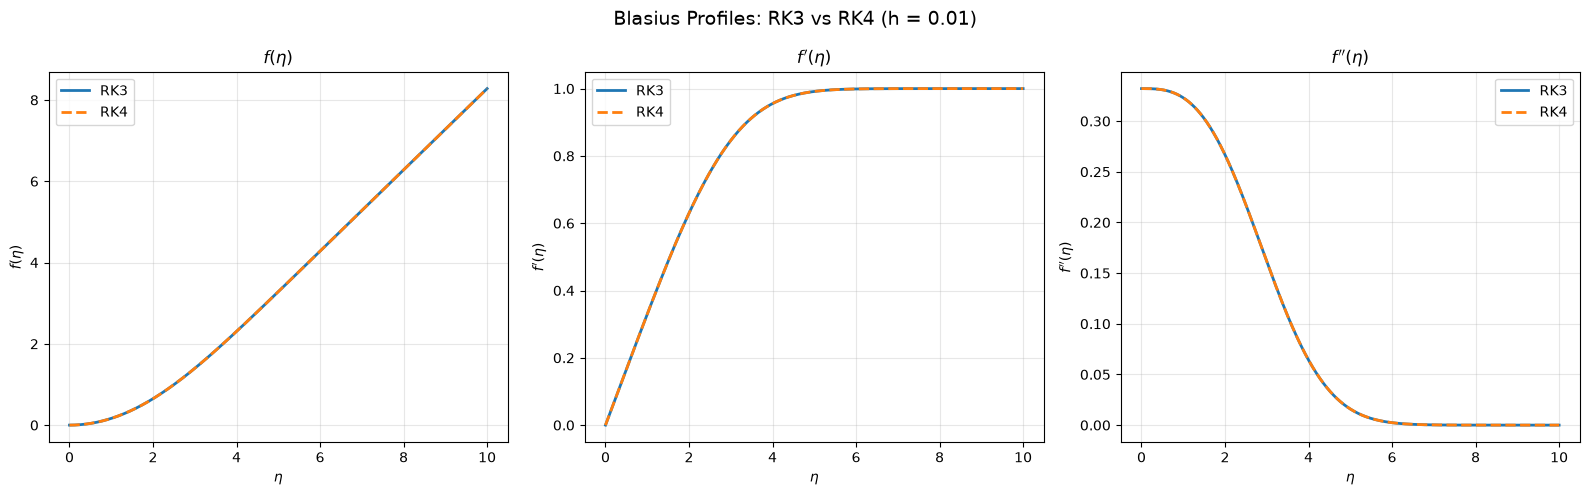

BLASIUS SOLUTION COMPARISON
RK3 shooting parameter = 0.332057336559
RK4 shooting parameter = 0.332057337205

RK3 final velocity      = 0.999999999999
RK4 final velocity      = 1.000000000000

RK3 final curvature     = 8.442739891149e-09
RK4 final curvature     = 8.442916760840e-09


In [8]:
# CONVERTED 3rd ORDER BLAUSIUS TO FIRST-ORDER ODE

import numpy as np
import matplotlib.pyplot as plt

def first_order(u1, u2, u3):

    Y = np.array([u1, u2, u3])
    G = np.array([[0, 1, 0],[0, 0, 1],[0, 0, -u1/2]])
    Y_d = G @ Y

    return Y_d



# IMPLEMENTING RK3

def RK3(s, h, eta_inf):

    N = int(round(eta_inf / h))
    Y = np.zeros((N + 1, 3))
    eta = np.linspace(0, eta_inf, N + 1)

    Y[0, 0] = 0
    Y[0, 1] = 0
    Y[0, 2] = s

    for i in range(N):
        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])
        K2 = h * first_order(Y[i, 0] + K1[0]/2,Y[i, 1] + K1[1]/2,Y[i, 2] + K1[2]/2)
        K3 = h * first_order(Y[i, 0] - K1[0] + 2*K2[0],Y[i, 1] - K1[1] + 2*K2[1],Y[i, 2] - K1[2] + 2*K2[2])
        Y[i+1] = Y[i] + (K1 + 4*K2 + K3) / 6

    return eta, Y
    



# IMPLEMENTING SHOOTING METHOD TO FIND THAT RANGE

def shooting_error(s, eta_inf, h):

    eta, Y = RK3(s, h, eta_inf)
    fp_final = Y[-1, 1]
    residual = fp_final - 1.0

    return residual


eta_inf = 10
h = 0.01
s_values = np.array([0.1, 0.2, 0.3, 0.5, 2.0])
R_values = np.array([shooting_error(s, eta_inf, h) for s in s_values])


print("SHOOTING METHOD: RESIDUAL CALCULATIONS")
print("=" * 55)
print(f"{'Initial curvature (s)':<25}{'Residual R(s)':<20}")
print("-" * 55)

for s, R in zip(s_values, R_values):
    print(f"{s:<25.6f}{R:<20.10f}")

print("=" * 55)


plt.figure(figsize=(9, 5))
plt.plot(s_values,R_values,marker='o',linestyle='-',linewidth=2,markersize=7,label='Shooting residual R(s)')
plt.axhline(y=0,linestyle='--',linewidth=1.5,label='R(s) = 0')
plt.xlabel('Initial slope, s = f"(0)', fontsize=12)
plt.ylabel('Residual, R(s)', fontsize=12)
plt.title('Shooting Residual versus Initial Slope',fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()




# BISECTION

def bisection_method(s_lower, s_upper, eta_inf, h, tol=1e-8, max_iter=100):

    R_lower = shooting_error(s_lower, eta_inf, h)
    R_upper = shooting_error(s_upper, eta_inf, h)

    if R_lower * R_upper >= 0:
        raise ValueError("Initial interval does not bracket a root.")

    print("BISECTION METHOD")
    print("=" * 85)
    print(f"{'Iter':<8}{'s_lower':<15}{'s_upper':<15}"
          f"{'s_mid':<15}{'R(s_mid)':<18}{'Error':<15}")
    print("-" * 85)

    for iteration in range(1, max_iter + 1):

        s_mid = (s_lower + s_upper) / 2.0
        R_mid = shooting_error(s_mid, eta_inf, h)
        error = (s_upper - s_lower) / 2.0

        print(f"{iteration:<8}{s_lower:<15.8f}{s_upper:<15.8f}"
              f"{s_mid:<15.8f}{R_mid:<18.8e}{error:<15.8e}")

        if abs(R_mid) < tol or error < tol:
            break

        if R_lower * R_mid < 0:
            s_upper = s_mid
            R_upper = R_mid
        else:
            s_lower = s_mid
            R_lower = R_mid

    print("=" * 85)
    print("Bisection method completed.")
    print(f"Final initial curvature f''(0) = {s_mid:.10f}")
    print(f"Final residual R(s) = {R_mid:.10e}")
    print(f"Number of iterations = {iteration}")

    return s_mid


s_lower = 0.3
s_upper = 0.5
s_bisection = bisection_method(s_lower,s_upper,eta_inf,h)






# Step-size convergence study using RK3

eta_inf = 10
h_values = np.array([0.4, 0.2, 0.1, 0.05, 0.025])
s_reference = 0.3320573362


def find_shooting_parameter(h, eta_inf):

    s_lower = 0.3
    s_upper = 0.5
    R_lower = shooting_error(s_lower, eta_inf, h)
    R_upper = shooting_error(s_upper, eta_inf, h)

    if R_lower * R_upper >= 0:
        raise ValueError("Initial interval does not bracket the root")

    tol = 1e-12

    for iteration in range(200):

        s_mid = (s_lower + s_upper) / 2

        R_mid = shooting_error(s_mid, eta_inf, h)

        if abs(s_upper - s_lower) / 2 < tol:
            break

        if R_lower * R_mid < 0:
            s_upper = s_mid
            R_upper = R_mid
        else:
            s_lower = s_mid
            R_lower = R_mid

    return s_mid

s_results = []

for h in h_values:

    s = find_shooting_parameter(h, eta_inf)
    s_results.append(s)

s_results = np.array(s_results)
errors = np.abs(s_results - s_reference)

observed_order = []

for i in range(len(h_values) - 1):

    p = np.log(errors[i] / errors[i+1]) / np.log(h_values[i] / h_values[i+1])
    observed_order.append(p)


print("\nRK3 CONVERGENCE ANALYSIS")
print("=" * 75)

print(f"{'Step size':<15}{'f''(0)':<20}{'Absolute error':<22}")

for i in range(len(h_values)):

    print(f"{h_values[i]:<15.4f}"f"{s_results[i]:<20.10f}"f"{errors[i]:<22.8e}")

print("\nOBSERVED ORDER OF ACCURACY")
print("-" * 45)

for i, p in enumerate(observed_order):

    print(f"h = {h_values[i]:.4f} to "
          f"h = {h_values[i+1]:.4f} : p = {p:.6f}")

plt.figure(figsize=(8, 5))
plt.loglog(h_values, errors, 'o-',linewidth=2,markersize=7,label='RK3 numerical error')
reference_line = errors[0] * (h_values / h_values[0])**3
plt.loglog(h_values, reference_line, '--',linewidth=1.5,label='Third-order reference slope')
plt.xlabel(r'Step size, $h$', fontsize=12)
plt.ylabel(r'Absolute error, $E(h)$', fontsize=12)
plt.title('RK3 Convergence Analysis', fontsize=14)
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()




# BLASIUS SOLUTION USING RK3

eta_inf = 10
h_plot = 0.01
s_plot = find_shooting_parameter(h_plot, eta_inf)
eta, Y = RK3(s_plot, h_plot, eta_inf)

f = Y[:, 0]
fp = Y[:, 1]
fpp = Y[:, 2]

print("SOLUTION PARAMETERS")
print("-" * 40)
print("Initial curvature f''(0):", s_plot)
print("Final velocity f'(eta_inf):", fp[-1])
print("Final similarity function:", f[-1])
print("Final curvature f''(eta_inf):", fpp[-1])




# PLOTTING ALL THREE QUANTITIES

plt.figure(figsize=(9, 6))
plt.plot(eta, f, linewidth=2, label=r'$f(\eta)$')
plt.plot(eta, fp, linewidth=2, label=r"$f'(\eta)$")
plt.plot(eta, fpp, linewidth=2, label=r"$f''(\eta)$")
plt.xlabel(r'Similarity coordinate, $\eta$', fontsize=12)
plt.ylabel('Dependent variables', fontsize=12)
plt.title('Blasius Velocity Profile and Similarity Functions',fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()





# RK4 IMPLEMENTATION FOR BLAUSIUS EQUATION


def RK4(s, h, eta_inf):

    N = int(round(eta_inf / h))
    if not np.isclose(N*h, eta_inf):
        raise ValueError("Invalid step size")

    eta = np.linspace(0, eta_inf, N+1)
    Y = np.zeros((N+1, 3))
    Y[0] = [0, 0, s]

    for i in range(N):

        K1 = h * first_order(*Y[i])
        K2 = h * first_order(*(Y[i] + K1/2))
        K3 = h * first_order(*(Y[i] + K2/2))
        K4 = h * first_order(*(Y[i] + K3))
        Y[i+1] = Y[i] + (K1 + 2*K2 + 2*K3 + K4)/6

    return eta, Y, Y[-1, 1] - 1


def error_RK4(s, h):
    residual = RK4(s, h, eta_inf)[2]

    return residual


def bisection_RK4(sl, su, eps, h):

    Rl = error_RK4(sl, h)
    Ru = error_RK4(su, h)

    if Rl * Ru >= 0:
        raise ValueError("Initial interval does not bracket the root")

    for iteration in range(200):

        s = (sl + su)/2
        Rs = error_RK4(s, h)

        if abs(Rs) < eps or (su-sl)/2 < eps:
            return s

        if Rl * Rs < 0:
            su = s
            Ru = Rs
        else:
            sl = s
            Rl = Rs

    return s





#############################################


# ==========================================
# CONVERGENCE COMPARISON: RK3 vs RK4
# ==========================================

eta_inf = 10

h_values = np.array([0.4, 0.2, 0.1, 0.05, 0.025])

# Accepted Blasius reference value
s_reference = 0.3320573362

# Arrays to store shooting parameters
s_RK3 = np.zeros(len(h_values))
s_RK4 = np.zeros(len(h_values))

# Calculate shooting parameters for both methods
for i, hi in enumerate(h_values):

    # RK3
    s_RK3[i] = find_shooting_parameter(hi, eta_inf)

    # RK4
    s_RK4[i] = bisection_RK4(0.2, 0.4, 1e-12, hi)


# Calculate absolute errors
error_values_RK3 = np.abs(s_RK3 - s_reference)
error_values_RK4 = np.abs(s_RK4 - s_reference)


# Calculate observed orders
order_RK3 = (
    np.log(error_values_RK3[:-1] / error_values_RK3[1:])
    / np.log(2)
)

order_RK4 = (
    np.log(error_values_RK4[:-1] / error_values_RK4[1:])
    / np.log(2)
)


# Print comparison table
print("SHOOTING PARAMETER CONVERGENCE: RK3 vs RK4")
print("=" * 105)

print(f"{'h':<12}{'RK3 s':<22}{'RK3 Error':<20}"
      f"{'RK4 s':<22}{'RK4 Error':<20}")

print("-" * 105)

for i, hi in enumerate(h_values):

    print(f"{hi:<12.4f}"
          f"{s_RK3[i]:<22.12f}"
          f"{error_values_RK3[i]:<20.6e}"
          f"{s_RK4[i]:<22.12f}"
          f"{error_values_RK4[i]:<20.6e}")


print("\nOBSERVED ORDER OF ACCURACY")
print("=" * 65)

print(f"{'Step-size transition':<30}{'RK3 Order':<15}{'RK4 Order':<15}")

for i in range(len(order_RK3)):

    print(f"{h_values[i]:.4f} -> {h_values[i+1]:.4f}"
          f"{order_RK3[i]:<15.6f}"
          f"{order_RK4[i]:<15.6f}")


# ==========================================
# COMBINED CONVERGENCE PLOT
# ==========================================

plt.figure(figsize=(9, 6))

plt.loglog(
    h_values, error_values_RK3,
    'o-', linewidth=2, markersize=7,
    label='RK3 numerical error'
)

plt.loglog(
    h_values, error_values_RK4,
    's-', linewidth=2, markersize=7,
    label='RK4 numerical error'
)

# Reference slopes
reference_RK3 = (
    error_values_RK3[0] * (h_values / h_values[0])**3
)

reference_RK4 = (
    error_values_RK4[0] * (h_values / h_values[0])**4
)

plt.loglog(
    h_values, reference_RK3,
    '--', linewidth=1.5,
    label=r'RK3 reference slope ($h^3$)'
)

plt.loglog(
    h_values, reference_RK4,
    '--', linewidth=1.5,
    label=r'RK4 reference slope ($h^4$)'
)

plt.xlabel(r'Step size, $h$', fontsize=12)
plt.ylabel(r'Absolute error in $f^{\prime\prime}(0)$', fontsize=12)

plt.title('Convergence Comparison: RK3 and RK4', fontsize=14)

plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()


# ==========================================
# BLASIUS PROFILES: RK3 vs RK4
# ==========================================

eta_inf = 10
h_plot = 0.01

# Find shooting parameters
s_plot_RK3 = find_shooting_parameter(h_plot, eta_inf)

s_plot_RK4 = bisection_RK4(0.2, 0.4, 1e-12, h_plot)


# Obtain numerical solutions
eta3, Y3 = RK3(s_plot_RK3, h_plot, eta_inf)

eta4, Y4, residual4 = RK4(s_plot_RK4, h_plot, eta_inf)


# Extract RK3 variables
f3 = Y3[:, 0]
fp3 = Y3[:, 1]
fpp3 = Y3[:, 2]


# Extract RK4 variables
f4 = Y4[:, 0]
fp4 = Y4[:, 1]
fpp4 = Y4[:, 2]


# Plot all three profiles
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

# f(eta)
ax[0].plot(eta3, f3, linewidth=2, label='RK3')
ax[0].plot(eta4, f4, '--', linewidth=2, label='RK4')
ax[0].set_xlabel(r'$\eta$')
ax[0].set_ylabel(r'$f(\eta)$')
ax[0].set_title(r'$f(\eta)$')
ax[0].legend()
ax[0].grid(True, alpha=0.3)


# f'(eta)
ax[1].plot(eta3, fp3, linewidth=2, label='RK3')
ax[1].plot(eta4, fp4, '--', linewidth=2, label='RK4')
ax[1].set_xlabel(r'$\eta$')
ax[1].set_ylabel(r"$f'(\eta)$")
ax[1].set_title(r"$f'(\eta)$")
ax[1].legend()
ax[1].grid(True, alpha=0.3)


# f''(eta)
ax[2].plot(eta3, fpp3, linewidth=2, label='RK3')
ax[2].plot(eta4, fpp4, '--', linewidth=2, label='RK4')
ax[2].set_xlabel(r'$\eta$')
ax[2].set_ylabel(r"$f''(\eta)$")
ax[2].set_title(r"$f''(\eta)$")
ax[2].legend()
ax[2].grid(True, alpha=0.3)


fig.suptitle(
    f'Blasius Profiles: RK3 vs RK4 (h = {h_plot})',
    fontsize=14
)

plt.tight_layout()
plt.show()


# Print solution parameters
print("BLASIUS SOLUTION COMPARISON")
print("=" * 60)

print(f"RK3 shooting parameter = {s_plot_RK3:.12f}")
print(f"RK4 shooting parameter = {s_plot_RK4:.12f}")

print(f"\nRK3 final velocity      = {fp3[-1]:.12f}")
print(f"RK4 final velocity      = {fp4[-1]:.12f}")

print(f"\nRK3 final curvature     = {fpp3[-1]:.12e}")
print(f"RK4 final curvature     = {fpp4[-1]:.12e}")










